# Netflix Country Analysis

## Project Overview
This project analyzes Netflix content based on country.
The analysis identifies countries with the most titles,
examines content distribution, and visualizes key findings
using Python, Pandas, and Matplotlib.

## Objectives
- Identify countries with the most Netflix titles.
- Analyze movies and TV shows by country.
- Handle missing country information.
- Visualize country-wise content distribution.
- Summarize the key findings.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("../Dataset/Dataset.csv")

df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [3]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDataset Information:")
df.info()

Dataset Shape: (8790, 10)

Column Names:
['show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in']

Missing Values:
show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8790 non-null   object
 1   type          8790 non-null   object
 2   title         8790 non-null   object
 3   director      8790 non-null   object
 4   country       8790 non-null   object
 5   date_added    8790 non-null   object
 6   release_year  8790 non-null   int64 
 7   rating        8790 non-null   object
 8   duration      8790 non-null   object
 9   listed_in     8790 non-null   object

In [4]:
df["country"].head(20)

0      United States
1             France
2      United States
3             Brazil
4      United States
5     United Kingdom
6      United States
7              India
8            Germany
9              India
10             India
11             India
12          Pakistan
13     United States
14     United States
15     United States
16     United States
17          Pakistan
18          Pakistan
19     United States
Name: country, dtype: object

In [ ]:
not_given_count = (df["country"] == "Not Given").sum()

print("Titles with country information unavailable:", not_given_count)
percentage = (not_given_count / len(df)) * 100

print(f"Percentage of titles with unavailable country information: {percentage:.2f}%")

Titles with country information unavailable: 287
Percentage of titles with unavailable country information: 3.27%


In [6]:
# Create a copy of the original dataset
country_df = df.copy()

# Exclude titles with unavailable country information
country_df = country_df[country_df["country"] != "Not Given"]

# Split multiple countries into separate rows
country_df["country"] = country_df["country"].str.split(", ")

# Create one row for each country
country_df = country_df.explode("country")

# Remove extra spaces
country_df["country"] = country_df["country"].str.strip()

# Display the first 15 rows
country_df[["title", "country"]].head(15)

,title,country
0,Dick Johnson Is Dead,United States
1,Ganglands,France
2,Midnight Mass,United States
3,Confessions of an Invisible Girl,Brazil
4,Sankofa,United States
5,The Great British Baking Show,United Kingdom
6,The Starling,United States
7,Motu Patlu in the Game of Zones,India
8,Je Suis Karl,Germany
9,Motu Patlu in Wonderland,India


In [7]:
# Count Netflix titles associated with each country
top_countries = country_df["country"].value_counts().head(10)

# Display the results
print("Top 10 Countries by Number of Netflix Titles:\n")
print(top_countries)

Top 10 Countries by Number of Netflix Titles:

country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Mexico             138
Name: count, dtype: int64


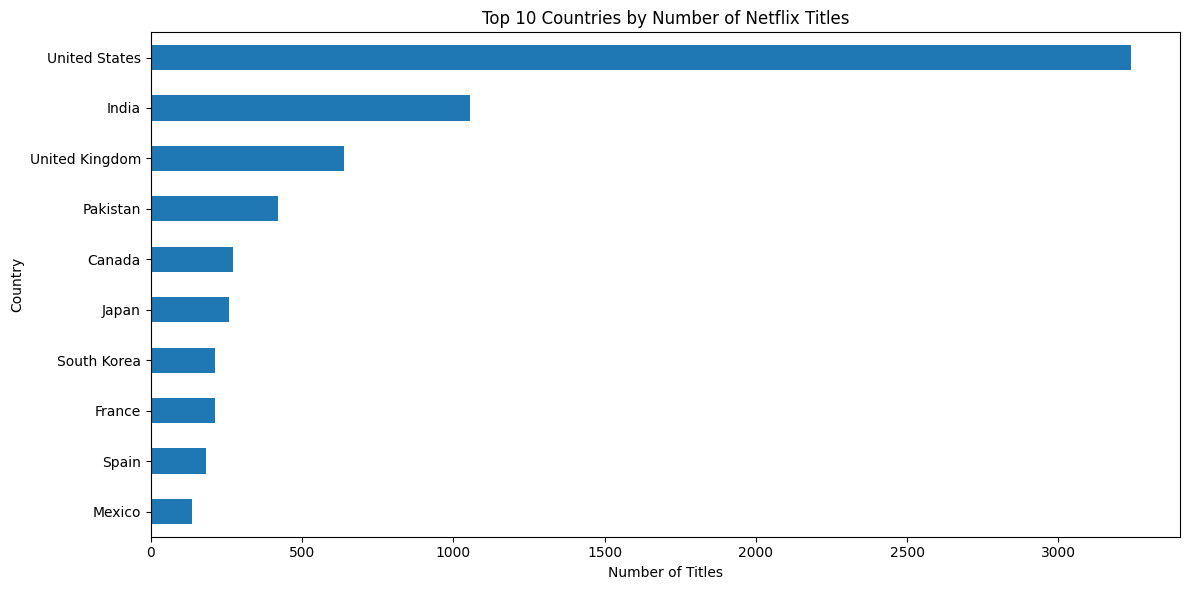

In [8]:
plt.figure(figsize=(12, 6))

top_countries.sort_values().plot(
    kind="barh",
    title="Top 10 Countries by Number of Netflix Titles"
)

plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.tight_layout()

plt.savefig("../Output/top_10_countries.png", dpi=300, bbox_inches="tight")

plt.show()

In [9]:
# Get the number of titles associated with the United States
us_count = top_countries["United States"]

# Get the number of titles associated with India
india_count = top_countries["India"]

# Calculate the difference between the two countries
difference = us_count - india_count

# Display the results
print("Netflix Country Analysis")
print("------------------------")
print("United States:", us_count)
print("India:", india_count)
print("Difference:", difference)

Netflix Country Analysis
------------------------
United States: 3240
India: 1057
Difference: 2183


In [10]:
# Calculate the percentage difference relative to India's count
percentage_difference = (difference / india_count) * 100

# Display the percentage difference
print(f"US count is {percentage_difference:.2f}% higher than India's count.")

US count is 206.53% higher than India's count.


In [11]:
# Convert the top 10 country counts into a DataFrame
ranking_df = top_countries.reset_index()

# Rename the columns to make them clear
ranking_df.columns = ["Country", "Number_of_Titles"]

# Add a ranking column starting from 1
ranking_df.insert(0, "Rank", range(1, len(ranking_df) + 1))

# Display the ranking table
print(ranking_df)

   Rank         Country  Number_of_Titles
0     1   United States              3240
1     2           India              1057
2     3  United Kingdom               638
3     4        Pakistan               421
4     5          Canada               271
5     6           Japan               259
6     7     South Korea               214
7     8          France               213
8     9           Spain               182
9    10          Mexico               138


In [13]:
# Save the country ranking table in the Output folder
ranking_df.to_csv(
    "../Output/top_10_country_ranking.csv",
    index=False
)

print("Country ranking table saved successfully!")

Country ranking table saved successfully!
